In [54]:
import os
print(os.environ.get("OMP_NUM_THREADS"))

3


In [55]:
#Prevent the potential memory leak by limiting OpenMP to one thread.
import os
os.environ["OMP_NUM_THREADS"] = "3"

#- MKL is Intel’s math library, often included with Anaconda to make calculations faster.
#- OpenMP lets calculations use multiple CPU threads at once.
#- In some Windows setups, K-means with MKL can fail to release a small amount of memory correctly after processing data. That is called a memory leak.
#- It usually matters only if you run K-means repeatedly or on large datasets: memory use could slowly grow.
#- Setting OMP_NUM_THREADS=1 tells it to use one CPU thread, avoiding that specific issue.
#For your Wine dataset example, you can safely continue, or add the setting to make the warning disappear.

In [56]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


In [57]:
# Load a real dataset: chemical measurements from wine samples
wine = load_wine()
X = wine.data


In [58]:
print(wine.feature_names)

['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


In [59]:
# K-means uses distances, so scaling features is important
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [60]:
# Important hyperparameters:
# n_clusters: expected number of groups
# init: initialization strategy for centroids
# n_init: number of different centroid initializations to try
# max_iter: maximum iterations per run
# random_state: makes results reproducible
kmeans = KMeans(
    n_clusters=4,
    init="k-means++",
    n_init=20,
    max_iter=100,
    random_state=42
)


In [61]:
# Fit the model and assign a cluster to every wine sample
clusters = kmeans.fit_predict(X_scaled)


In [62]:
# Model outputs
print("Cluster labels for first 10 samples:", clusters[:10])
print("Cluster centers (scaled feature space):")
print(kmeans.cluster_centers_)


Cluster labels for first 10 samples: [0 0 0 0 3 0 0 0 0 0]
Cluster centers (scaled feature space):
[[ 9.75769737e-01 -3.63784637e-01  2.45344690e-01 -8.14164939e-01
   4.35595246e-01  8.99019294e-01  9.84620622e-01 -6.18541556e-01
   5.47305267e-01  2.45503572e-01  4.77045780e-01  7.70867718e-01
   1.25833074e+00]
 [ 1.86543138e-01  9.04971453e-01  2.49210264e-01  5.83703484e-01
  -5.06353947e-02 -9.88556997e-01 -1.23619475e+00  7.16841717e-01
  -7.49607560e-01  9.88498285e-01 -1.19129878e+00 -1.30153966e+00
  -3.80044610e-01]
 [-9.07722354e-01 -5.40506402e-01 -6.51727662e-01  1.59668391e-01
  -7.16754611e-01 -4.55064160e-01 -2.41557402e-01  3.32442343e-01
  -4.34145011e-01 -9.20355551e-01  5.21681412e-01  7.89134093e-02
  -7.84248573e-01]
 [-7.57256669e-01 -4.36484792e-04  1.24913238e-01  3.10087011e-01
   3.71632873e-01  6.71417893e-01  5.96189359e-01 -5.53978069e-01
   9.02258837e-01 -7.07693540e-01  2.98636508e-01  6.14710874e-01
  -5.27407562e-01]]


In [63]:
# Lower inertia generally means tighter clusters
print("Inertia:", kmeans.inertia_)


Inertia: 1175.351881365828


In [64]:
# Higher silhouette score (closer to 1) indicates better-separated clusters
print("Silhouette score:", silhouette_score(X_scaled, clusters))


Silhouette score: 0.2586075384934024


In [65]:
# The dataset has known wine classes, but K-means does not use them for training.
print("True class labels for first 10 samples:", wine.target[:10])

True class labels for first 10 samples: [0 0 0 0 0 0 0 0 0 0]


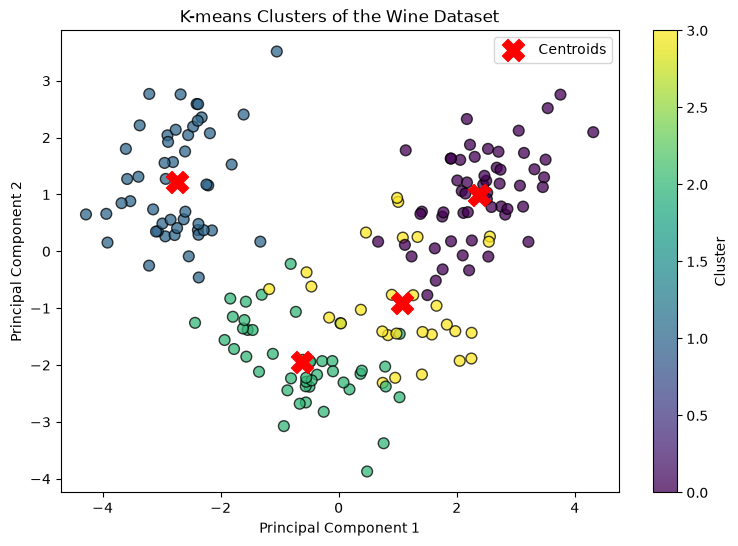

In [66]:
#-------------------
#VISUALIZAITON
#-------------------
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA


# Reduce 13 features to 2 dimensions only for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Convert the K-means centers into the same 2D PCA space
centers_pca = pca.transform(kmeans.cluster_centers_)

# Plot each cluster
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="viridis",
    s=60,
    alpha=0.75,
    edgecolors="black"
)

# Plot centroid locations
plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    c="red",
    marker="X",
    s=250,
    label="Centroids"
)

plt.title("K-means Clusters of the Wine Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.legend()
plt.show()